# ET0737 Mini Project: Customer Churn Prediction

**Task type:** Classification

**Dataset:** IBM Telco Customer Churn (7043 customers, 21 columns)

**Source:** https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

## Workflow
Raw Data -> EDA -> Cleaning -> Feature Engineering -> Encoding -> Train/Val/Test Split -> Model Training -> Hyperparameter Tuning -> Evaluation -> Save Model

## Objective
Predict whether a telecom customer will leave (churn) so the company can target them with
retention offers before they cancel.

## Part 1 - Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, classification_report
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## Part 2 - Load the Dataset

In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Part 3 - Explore the Data

Check the data types, missing values and how balanced the target column is.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# TotalCharges is stored as text, so blank entries do not show up as NaN.
# Count them separately by stripping the spaces first.
blank_totalcharges = (df["TotalCharges"].str.strip() == "").sum()
print("\nBlank TotalCharges values:", blank_totalcharges)

print("\nDuplicated rows:", df.duplicated().sum())

Missing values per column:
Series([], dtype: int64)

Blank TotalCharges values: 11

Duplicated rows: 0


In [5]:
print("Churn counts:")
print(df["Churn"].value_counts())
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True).round(3))

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


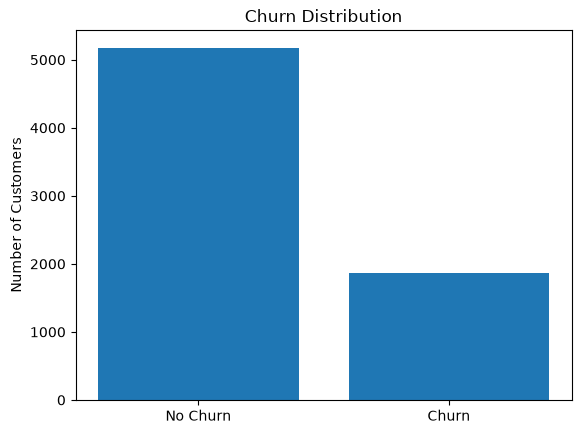

In [6]:
churn_counts = df["Churn"].value_counts().sort_index()
plt.bar(["No Churn", "Churn"], churn_counts)
plt.ylabel("Number of Customers")
plt.title("Churn Distribution")
plt.show()

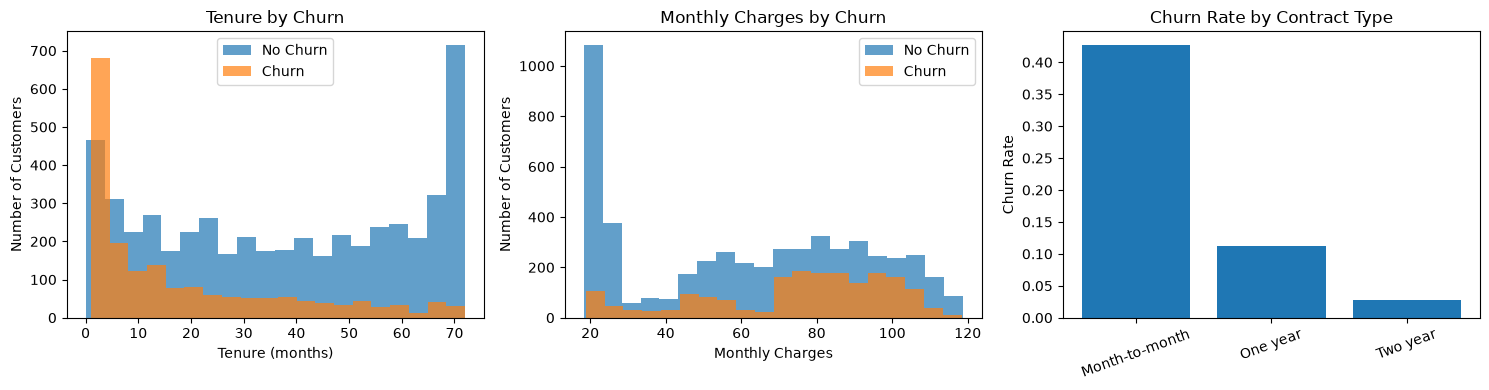

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df[df["Churn"] == "No"]["tenure"], bins=20, alpha=0.7, label="No Churn")
axes[0].hist(df[df["Churn"] == "Yes"]["tenure"], bins=20, alpha=0.7, label="Churn")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Number of Customers")
axes[0].set_title("Tenure by Churn")
axes[0].legend()

axes[1].hist(df[df["Churn"] == "No"]["MonthlyCharges"], bins=20, alpha=0.7, label="No Churn")
axes[1].hist(df[df["Churn"] == "Yes"]["MonthlyCharges"], bins=20, alpha=0.7, label="Churn")
axes[1].set_xlabel("Monthly Charges")
axes[1].set_ylabel("Number of Customers")
axes[1].set_title("Monthly Charges by Churn")
axes[1].legend()

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index")
axes[2].bar(contract_churn.index, contract_churn["Yes"])
axes[2].set_ylabel("Churn Rate")
axes[2].set_title("Churn Rate by Contract Type")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Part 4 - Data Cleaning

Keep the original dataframe untouched and work on a copy.

In [8]:
clean_df = df.copy()

# customerID is just an identifier, it has no predictive value
clean_df = clean_df.drop(columns=["customerID"])

# TotalCharges was read as text because of the blank values, convert it to numbers.
# errors="coerce" turns the blanks into NaN so we can fill them.
clean_df["TotalCharges"] = pd.to_numeric(clean_df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", clean_df["TotalCharges"].isnull().sum())

# These are new customers with tenure = 0 who have not been billed yet.
print(clean_df[clean_df["TotalCharges"].isnull()][["tenure", "MonthlyCharges"]].head())

Missing TotalCharges after conversion: 11
      tenure  MonthlyCharges
488        0           52.55
753        0           20.25
936        0           80.85
1082       0           25.75
1340       0           56.05


In [9]:
# Fill with the median because it is not affected by extreme values
clean_df["TotalCharges"] = clean_df["TotalCharges"].fillna(clean_df["TotalCharges"].median())

print("Missing values left:", clean_df.isnull().sum().sum())

Missing values left: 0


In [10]:
# Check for outliers using the IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound


numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in numeric_cols:
    outliers, lower, upper = detect_outliers_iqr(clean_df, col)
    print(f"{col}: {len(outliers)} outliers (bounds {lower:.2f} to {upper:.2f})")

tenure: 0 outliers (bounds -60.00 to 124.00)
MonthlyCharges: 0 outliers (bounds -46.02 to 171.38)
TotalCharges: 0 outliers (bounds -4674.34 to 8863.16)


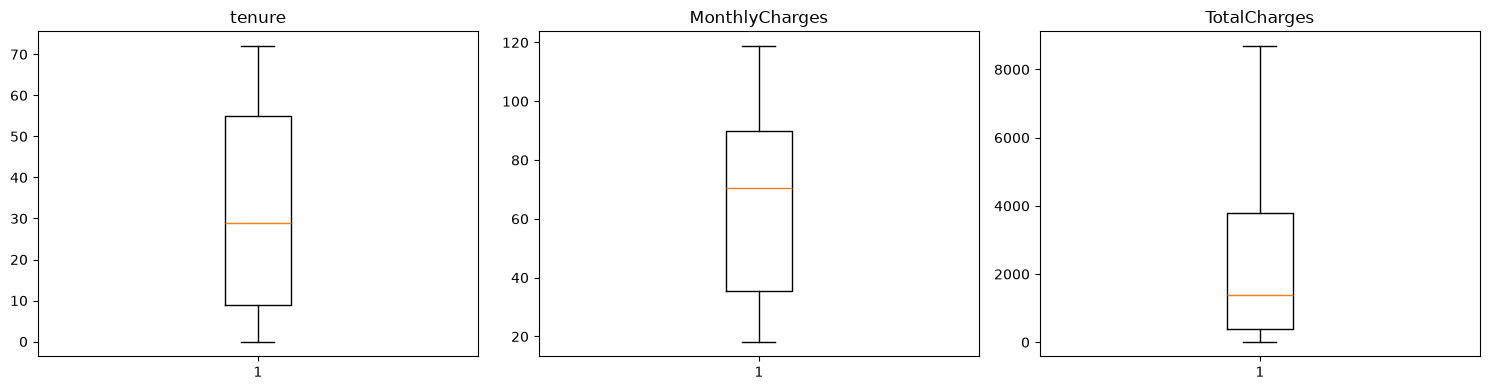

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(clean_df[col])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

clean_df[numeric_cols].describe()

No outliers were found, which makes sense because these columns are naturally limited
(tenure is capped at 72 months and the charges are normal monthly bills). So we do not
remove any rows here.

## Part 5 - Feature Engineering

Create a few new columns from the existing ones to give the models more useful information.

In [12]:
# How many optional services the customer subscribes to.
# "No internet service" is counted as a No.
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

clean_df["TotalServices"] = (clean_df[service_cols] == "Yes").sum(axis=1)

# Average amount billed per month of tenure. Add 1 to avoid dividing by zero.
clean_df["AvgChargePerMonth"] = clean_df["TotalCharges"] / (clean_df["tenure"] + 1)

# Group tenure into new / medium / long term customers
clean_df["TenureGroup"] = pd.cut(
    clean_df["tenure"],
    bins=[-1, 12, 36, 72],
    labels=["New", "Medium", "Long"]
)

clean_df[["tenure", "TenureGroup", "TotalServices", "AvgChargePerMonth"]].head()

,tenure,TenureGroup,TotalServices,AvgChargePerMonth
0,1,New,1,14.925000
1,34,Medium,2,53.985714
2,2,New,2,36.050000
3,45,Long,3,40.016304
4,2,New,0,50.550000


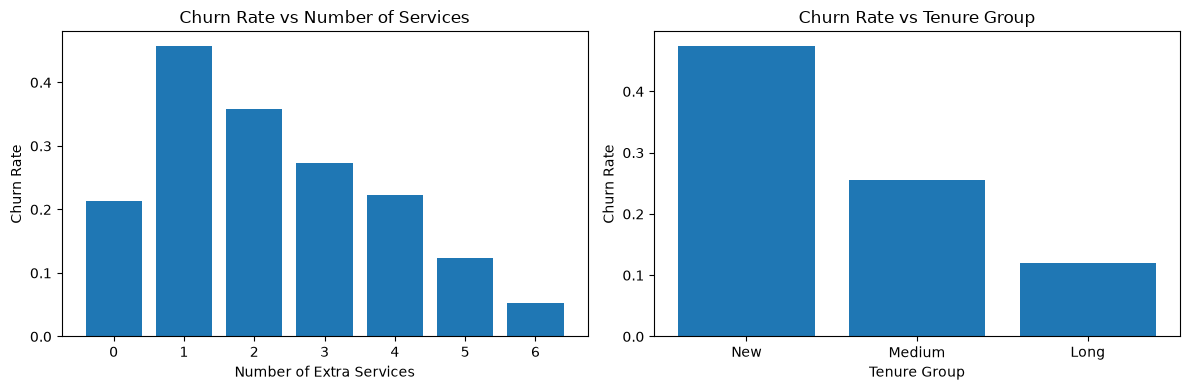

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

services_churn = clean_df.groupby("TotalServices")["Churn"].apply(lambda x: (x == "Yes").mean())
axes[0].bar(services_churn.index, services_churn.values)
axes[0].set_xlabel("Number of Extra Services")
axes[0].set_ylabel("Churn Rate")
axes[0].set_title("Churn Rate vs Number of Services")

tenure_churn = clean_df.groupby("TenureGroup", observed=True)["Churn"].apply(lambda x: (x == "Yes").mean())
axes[1].bar(tenure_churn.index.astype(str), tenure_churn.values)
axes[1].set_xlabel("Tenure Group")
axes[1].set_ylabel("Churn Rate")
axes[1].set_title("Churn Rate vs Tenure Group")

plt.tight_layout()
plt.show()

## Part 6 - Encode Categorical Variables

Models only accept numbers, so convert the target to 0/1 and one-hot encode the
categorical columns.

In [14]:
model_df = clean_df.copy()

# Target: No = 0, Yes = 1
model_df["Churn"] = model_df["Churn"].map({"No": 0, "Yes": 1})

categorical_cols = model_df.select_dtypes(exclude=["number"]).columns.tolist()
print("Categorical columns to encode:", len(categorical_cols))
print(categorical_cols)

Categorical columns to encode: 16
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [15]:
# drop_first=True removes one column per category to avoid duplicated information
model_df = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)

print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (7043, 35)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,TotalServices,AvgChargePerMonth,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_Medium,TenureGroup_Long
0,0,1,29.85,29.85,0,1,14.925000,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False
1,0,34,56.95,1889.50,0,2,53.985714,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True,True,False
2,0,2,53.85,108.15,1,2,36.050000,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False
3,0,45,42.30,1840.75,0,3,40.016304,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False,False,True
4,0,2,70.70,151.65,1,0,50.550000,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False


## Part 7 - Train / Validation / Test Split

The project requires three separate sets. Split twice to get 60% train, 20% validation
and 20% test. `stratify` keeps the same churn percentage in every set.

In [16]:
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

# First split: 60% train, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=RANDOM_SEED, stratify=y
)

# Second split: cut the 40% in half to get 20% validation and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_SEED, stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nChurn rate in each set:")
print("Train:", round(y_train.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Test:", round(y_test.mean(), 3))

Train: (4225, 34)
Validation: (1409, 34)
Test: (1409, 34)

Churn rate in each set:
Train: 0.265
Validation: 0.265
Test: 0.265


## Part 8 - Model Training

Train five different models and compare them. Each one is put inside a Pipeline so the
StandardScaler is fitted only on the training data. This prevents data leakage, because
the validation and test sets are only transformed, never used for fitting.

**Why these five.** The module brief names four algorithms for a classification task: Logistic Regression, SVM, Decision Trees, and Neural Networks (MLP). We added Random Forest as a fifth because it is a direct extension of the Decision Tree we are already covering, and it is a standard way to check whether averaging many trees fixes a single tree's tendency to overfit. Together these five span what we actually want to compare: one linear baseline (Logistic Regression), two tree-based methods of different complexity (Decision Tree, Random Forest), one margin-based method (SVM), and one that can learn non-linear boundaries directly (MLP). If a simple linear model wins against all of these, that is itself an informative result, not just a formality.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier


def make_pipeline(model):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])


models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(random_state=RANDOM_SEED)),
    "Random Forest": make_pipeline(RandomForestClassifier(random_state=RANDOM_SEED)),
    "SVM": make_pipeline(SVC(random_state=RANDOM_SEED)),
    "Neural Network (MLP)": make_pipeline(MLPClassifier(max_iter=1500, random_state=RANDOM_SEED))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained


Random Forest trained


SVM trained


Neural Network (MLP) trained


The neural network needs `max_iter=1500`. At the default 500 it stops before the loss settles and sklearn prints a ConvergenceWarning during cross-validation, which means the score would be measuring an unfinished model rather than a real comparison.

In [18]:
# Quick look at how each model does on the validation set before any tuning
results = []

for name, model in models.items():
    y_pred = model.predict(X_val)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

baseline_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
baseline_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.817,0.693,0.556,0.617
4,Neural Network (MLP),0.769,0.563,0.583,0.573
2,Random Forest,0.798,0.663,0.484,0.560
3,SVM,0.802,0.685,0.471,0.558
1,Decision Tree,0.723,0.481,0.540,0.509


## Part 9 - Hyperparameter Tuning

Use GridSearchCV to search for better settings. The `model__` prefix tells the grid which
step of the Pipeline the parameter belongs to.

For Logistic Regression we also try `class_weight="balanced"`. Only about 26% of customers
churn, so without this the model leans towards always predicting "No Churn".

In [19]:
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
    param_grid=lr_param_grid, cv=5, scoring="f1"
)
lr_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 3))

Best Logistic Regression parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best CV F1-score: 0.626


In [20]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_SEED)),
    param_grid=rf_param_grid, cv=5, scoring="f1"
)
rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 3))

Best Random Forest parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1-score: 0.58


In [21]:
dt_param_grid = {
    "model__max_depth": [3, 5, 6, 10],
    "model__min_samples_leaf": [1, 10, 20]
}

dt_grid = GridSearchCV(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_SEED)),
    param_grid=dt_param_grid, cv=5, scoring="f1"
)
dt_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 3))

Best Decision Tree parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 20}
Best CV F1-score: 0.577


SVM and the neural network were left untuned in the first version of this notebook. We are tuning them properly here instead of just excluding them, so the comparison in Part 11 is fair across all five models, not four tuned ones and two left at defaults.

In [22]:
svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["rbf", "linear"],
    "model__class_weight": [None, "balanced"]
}

svm_grid = GridSearchCV(
    make_pipeline(SVC(random_state=RANDOM_SEED)),
    param_grid=svm_param_grid, cv=5, scoring="f1"
)
svm_grid.fit(X_train, y_train)

print("Best SVM parameters:", svm_grid.best_params_)
print("Best CV F1-score:", round(svm_grid.best_score_, 3))

Best SVM parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__kernel': 'rbf'}
Best CV F1-score: 0.622


For the neural network we search over `alpha`, which is its L2 regularization strength (the same idea as Logistic Regression's `C`, just inverted: higher `alpha` means more regularization). If the MLP's overfitting problem from Part 8's baseline is really about needing more regularization rather than the model family being a poor fit, stronger regularization here should close some of that gap.

In [23]:
mlp_param_grid = {
    "model__hidden_layer_sizes": [(50,), (100,)],
    "model__alpha": [0.0001, 0.001, 0.01, 0.1]
}

mlp_grid = GridSearchCV(
    make_pipeline(MLPClassifier(max_iter=1500, random_state=RANDOM_SEED)),
    param_grid=mlp_param_grid, cv=5, scoring="f1"
)
mlp_grid.fit(X_train, y_train)

print("Best MLP parameters:", mlp_grid.best_params_)
print("Best CV F1-score:", round(mlp_grid.best_score_, 3))

Best MLP parameters: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (100,)}
Best CV F1-score: 0.554


Even with `alpha` pushed up to 0.1 (a hundred times the default), the MLP's cross-validated F1 is still well below Logistic Regression's. That confirms the earlier finding from Part 10 was not just a missing regularization setting: this model family does not fit the data better than a straight line does, no matter how it is regularized. Logistic Regression's own coefficient on `C` already found the right amount of regularization for the model that actually works here.

In [24]:
# Replace the untuned models with the tuned ones
tuned_models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "SVM": svm_grid.best_estimator_,
    "Neural Network (MLP)": mlp_grid.best_estimator_
}

print("Tuned models ready:", list(tuned_models.keys()))

Tuned models ready: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM', 'Neural Network (MLP)']


## Part 10 - Overfitting Check

Compare the training score against the validation score. If the training score is much
higher, the model has memorised the training data instead of learning the general pattern.

In [25]:
overfit_results = []

for name, model in tuned_models.items():
    train_f1 = f1_score(y_train, model.predict(X_train))
    val_f1 = f1_score(y_val, model.predict(X_val))
    overfit_results.append({
        "Model": name,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Gap": train_f1 - val_f1
    })

overfit_df = pd.DataFrame(overfit_results).sort_values("Gap", ascending=False)
overfit_df.round(3)

,Model,Train F1,Validation F1,Gap
4,Neural Network (MLP),0.835,0.561,0.273
2,Random Forest,0.764,0.563,0.201
1,Decision Tree,0.614,0.579,0.035
0,Logistic Regression,0.637,0.633,0.004
3,SVM,0.631,0.628,0.003


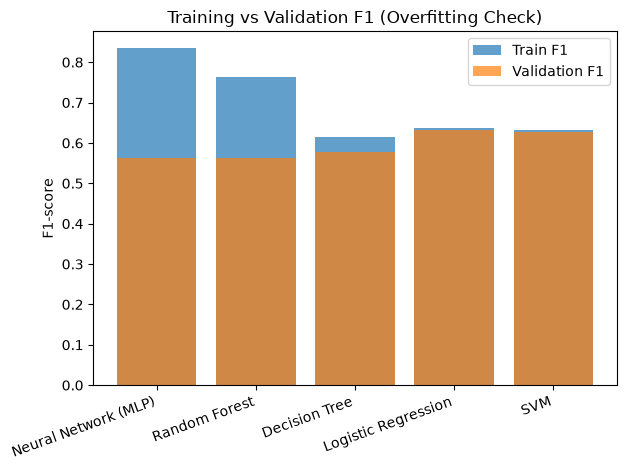

In [26]:
plt.bar(overfit_df["Model"], overfit_df["Train F1"], alpha=0.7, label="Train F1")
plt.bar(overfit_df["Model"], overfit_df["Validation F1"], alpha=0.7, label="Validation F1")
plt.ylabel("F1-score")
plt.title("Training vs Validation F1 (Overfitting Check)")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

The untuned Decision Tree originally had a very large gap because by default it keeps
splitting until every training customer is classified perfectly. Limiting `max_depth` and
`min_samples_leaf` through GridSearchCV in Part 9 is a form of regularization and it
brought the gap back down.

## Part 11 - Model Comparison

Compare all the tuned models on the validation set and pick the best one.

In [27]:
comparison_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_val)
    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred)
    })

comparison_df = pd.DataFrame(comparison_results).sort_values("F1-score", ascending=False).reset_index(drop=True)
comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.747,0.515,0.821,0.633
1,SVM,0.744,0.511,0.816,0.628
2,Decision Tree,0.801,0.659,0.516,0.579
3,Random Forest,0.800,0.669,0.487,0.563
4,Neural Network (MLP),0.767,0.561,0.561,0.561


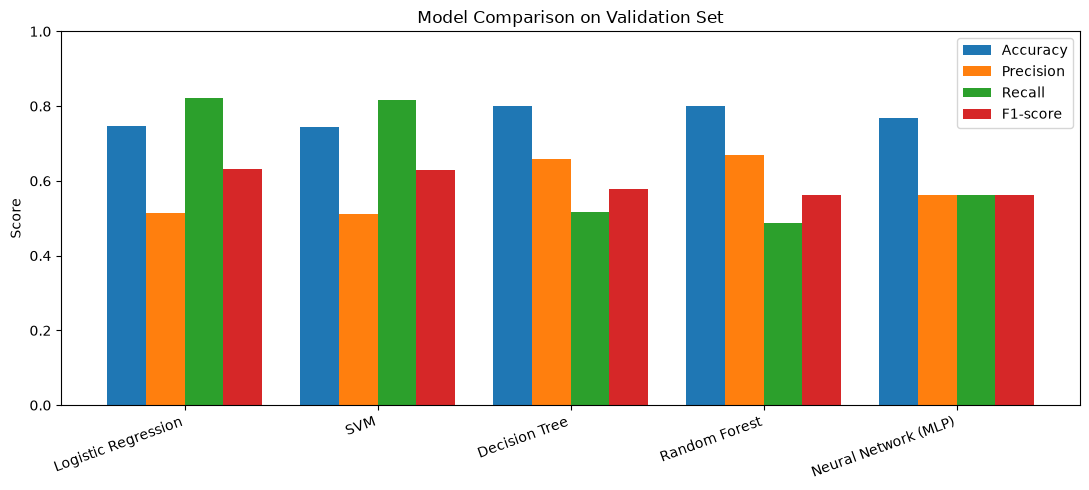

In [28]:
x = np.arange(len(comparison_df))
width = 0.2

plt.figure(figsize=(11, 5))
plt.bar(x - 1.5 * width, comparison_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5 * width, comparison_df["Precision"], width, label="Precision")
plt.bar(x + 0.5 * width, comparison_df["Recall"], width, label="Recall")
plt.bar(x + 1.5 * width, comparison_df["F1-score"], width, label="F1-score")

plt.xticks(x, comparison_df["Model"], rotation=20, ha="right")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Comparison on Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
best_model_name = comparison_df.loc[0, "Model"]
best_model = tuned_models[best_model_name]

print("Best model:", best_model_name)

Best model: Logistic Regression


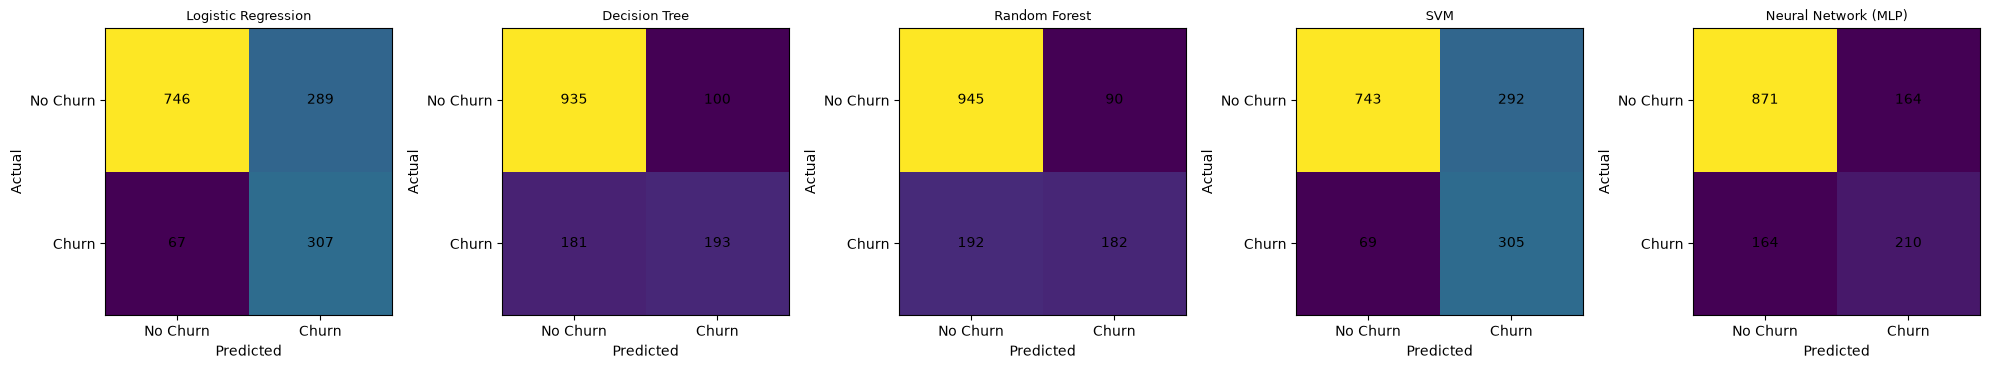

In [30]:
# Confusion matrices on the validation set
fig, axes = plt.subplots(1, len(tuned_models), figsize=(20, 4))

for ax, (name, model) in zip(axes, tuned_models.items()):
    cm = confusion_matrix(y_val, model.predict(X_val))
    ax.imshow(cm)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Churn", "Churn"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["No Churn", "Churn"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Part 12 - Threshold Experiment

By default the model predicts "Churn" when the predicted probability is above 0.5, but 0.5 is
just a convention, not a rule. Moving it changes the balance between the two kinds of mistake:

- a **missed churner** means the customer leaves and we lose all their future revenue
- a **false alarm** means we send a discount to somebody who was going to stay anyway

For this business those are not equally bad. Part 17 estimates that an at-risk customer is worth
about $277 on average, and the most valuable ones are worth over $1,500, while a retention offer
costs the company maybe $20 to $50. Losing a customer is far more expensive than a wasted
discount, so we would rather over-flag than under-flag.

That means F1 is the wrong thing to optimise here, because F1 treats precision and recall as
equally important. We use the **F2 score** instead, which is the same idea but weights recall
twice as heavily as precision. We still plot F1 for comparison so the difference is visible.

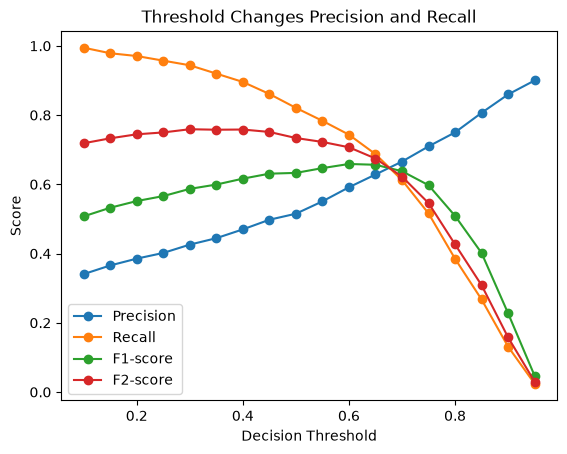

In [31]:
y_prob_val = best_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.05)
precision_values, recall_values, f1_values, f2_values = [], [], [], []

for threshold in thresholds:
    y_pred_threshold = (y_prob_val >= threshold).astype(int)
    precision_values.append(precision_score(y_val, y_pred_threshold, zero_division=0))
    recall_values.append(recall_score(y_val, y_pred_threshold, zero_division=0))
    f1_values.append(f1_score(y_val, y_pred_threshold, zero_division=0))
    # beta=2 makes recall count twice as much as precision
    f2_values.append(fbeta_score(y_val, y_pred_threshold, beta=2, zero_division=0))

plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")
plt.plot(thresholds, f1_values, marker="o", label="F1-score")
plt.plot(thresholds, f2_values, marker="o", label="F2-score")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Changes Precision and Recall")
plt.legend()
plt.show()

In [32]:
threshold_df = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1-score": f1_values,
    "F2-score": f2_values
})

best_threshold = threshold_df.loc[threshold_df["F2-score"].idxmax(), "Threshold"]
f1_threshold = threshold_df.loc[threshold_df["F1-score"].idxmax(), "Threshold"]

print("Threshold chosen (best F2-score):", round(best_threshold, 2))
print("For comparison, best F1-score would give:", round(f1_threshold, 2))

threshold_df.round(3)

Threshold chosen (best F2-score): 0.3
For comparison, best F1-score would give: 0.6


,Threshold,Precision,Recall,F1-score,F2-score
0,0.10,0.341,0.995,0.508,0.719
1,0.15,0.366,0.979,0.532,0.733
2,0.20,0.385,0.971,0.552,0.744
3,0.25,0.402,0.957,0.566,0.750
4,0.30,0.426,0.944,0.587,0.759
5,0.35,0.444,0.920,0.599,0.758
6,0.40,0.470,0.896,0.616,0.758
7,0.45,0.498,0.861,0.631,0.751
8,0.50,0.515,0.821,0.633,0.734
9,0.55,0.551,0.783,0.647,0.722


## Part 13 - Final Evaluation on the Test Set

The test set has not been used at all until now. We only look at it once, using the model
and threshold chosen from the validation set.

In [33]:
y_prob_test = best_model.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_test),
    "Precision": precision_score(y_test, y_pred_test),
    "Recall": recall_score(y_test, y_pred_test),
    "F1-score": f1_score(y_test, y_pred_test),
    "F2-score": fbeta_score(y_test, y_pred_test, beta=2)
}

print("Final test results for", best_model_name, "at threshold", round(best_threshold, 2))
print("Accuracy :", round(test_metrics["Accuracy"], 3))
print("Precision:", round(test_metrics["Precision"], 3))
print("Recall   :", round(test_metrics["Recall"], 3))
print("F1-score :", round(test_metrics["F1-score"], 3))
print("F2-score :", round(test_metrics["F2-score"], 3))

Final test results for Logistic Regression at threshold 0.3
Accuracy : 0.655
Precision: 0.431
Recall   : 0.928
F1-score : 0.588
F2-score : 0.754


In [34]:
print(classification_report(y_test, y_pred_test, target_names=["No Churn", "Churn"]))

              precision    recall  f1-score   support

    No Churn       0.96      0.56      0.70      1035
       Churn       0.43      0.93      0.59       374

    accuracy                           0.66      1409
   macro avg       0.69      0.74      0.65      1409
weighted avg       0.82      0.66      0.67      1409



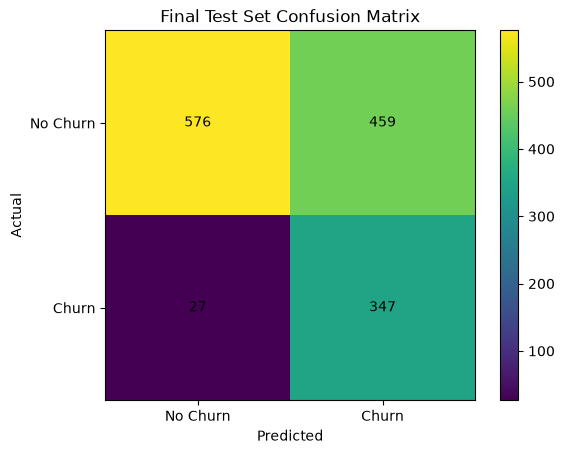

True Negatives (correctly kept): 576
False Positives (false alarms): 459
False Negatives (missed churners): 27
True Positives (churners caught): 347


In [35]:
cm = confusion_matrix(y_test, y_pred_test)

plt.imshow(cm)
plt.title("Final Test Set Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True Negatives (correctly kept):", tn)
print("False Positives (false alarms):", fp)
print("False Negatives (missed churners):", fn)
print("True Positives (churners caught):", tp)

## Part 14 - Cross-Validation Check

The results above come from one particular split. Cross-validation repeats the training on
5 different splits so we can check that the winning model is not just lucky.

In [36]:
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

cv_results = []

for name, model in tuned_models.items():
    scores = cross_val_score(model, X_trainval, y_trainval, cv=5, scoring="f1")
    cv_results.append({
        "Model": name,
        "Mean F1": scores.mean(),
        "Std Dev": scores.std()
    })
    print(name, "->", scores.round(3))

cv_df = pd.DataFrame(cv_results).sort_values("Mean F1", ascending=False)
cv_df.round(3)

Logistic Regression -> [0.628 0.637 0.632 0.626 0.626]
Decision Tree -> [0.547 0.595 0.556 0.617 0.541]


Random Forest -> [0.571 0.603 0.549 0.591 0.585]


SVM -> [0.628 0.636 0.627 0.609 0.63 ]


Neural Network (MLP) -> [0.536 0.573 0.526 0.545 0.536]


,Model,Mean F1,Std Dev
0,Logistic Regression,0.630,0.004
3,SVM,0.626,0.009
2,Random Forest,0.580,0.019
1,Decision Tree,0.571,0.030
4,Neural Network (MLP),0.543,0.016


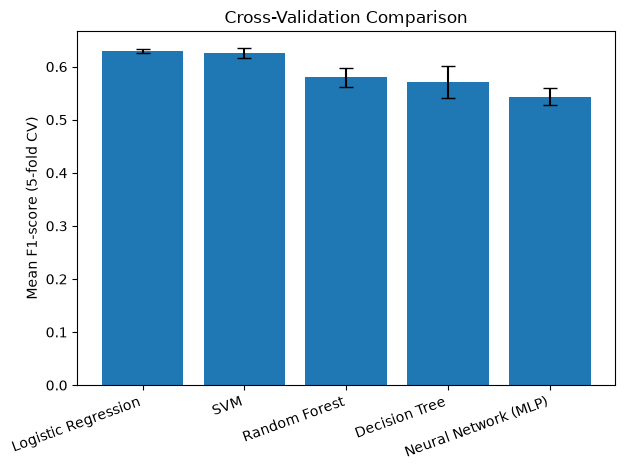

In [37]:
plt.bar(cv_df["Model"], cv_df["Mean F1"], yerr=cv_df["Std Dev"], capsize=5)
plt.ylabel("Mean F1-score (5-fold CV)")
plt.title("Cross-Validation Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Part 15 - Which Features Matter Most

Logistic Regression gives a coefficient for every feature. A positive coefficient pushes the
prediction towards churn and a negative one pushes it towards staying.

In [38]:
final_model = best_model.named_steps["model"]

if hasattr(final_model, "coef_"):
    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Coefficient": final_model.coef_[0]
    })
    importance_df["Absolute"] = importance_df["Coefficient"].abs()
    importance_df = importance_df.sort_values("Absolute", ascending=False).head(10)
else:
    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Coefficient": final_model.feature_importances_
    }).sort_values("Coefficient", ascending=False).head(10)

importance_df[["Feature", "Coefficient"]].round(3)

,Feature,Coefficient
5,AvgChargePerMonth,-1.741
1,tenure,-1.139
12,InternetService_Fiber optic,1.024
2,MonthlyCharges,-0.885
27,Contract_Two year,-0.678
3,TotalCharges,0.474
25,StreamingMovies_Yes,0.361
26,Contract_One year,-0.311
23,StreamingTV_Yes,0.303
11,MultipleLines_Yes,0.279


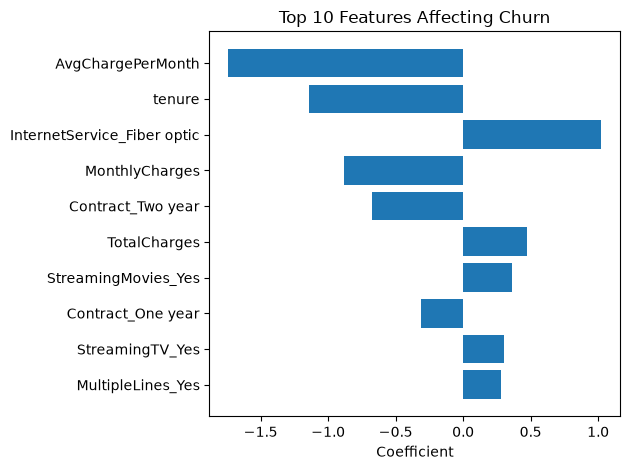

In [39]:
plt.barh(importance_df["Feature"], importance_df["Coefficient"])
plt.xlabel("Coefficient")
plt.title("Top 10 Features Affecting Churn")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Some of these coefficients need to be read carefully. `MonthlyCharges` comes out negative,
which looks wrong at first because a bigger bill should not make a customer more loyal. The
reason is that several columns carry overlapping information: the monthly bill is basically
decided by which internet type and services the customer has. Once `Fiber optic` is in the
model with a large positive coefficient, `MonthlyCharges` ends up taking a negative value to
balance it out. The same happens with `AvgChargePerMonth`, which we created from
`TotalCharges` and `tenure`.

So for the business conclusions we only rely on the features that are stable and easy to
explain (contract length, tenure, internet type, payment method) and we do not read too much
into the individual charge coefficients.

## Part 16 - Regression: How Long Does a Customer Last?

So far the project only does classification. The module also covers regression, and knowing
*whether* a customer will leave is not very useful on its own. A customer paying $20 a month is
not worth the same retention effort as one paying $110 a month.

So we add a second model, this time a regression, to answer a different question: **if we manage
to keep this customer, how long would they stay with us?** That is the number we need, because
the money the company loses when somebody leaves is the money they would have paid if they had
stayed.

To answer that we train on the customers who have **not** churned, because they are the ones
showing us what staying looks like. We first tried training on the customers who already left,
but that model learned "how quickly do people leave" instead, and it predicted such short
lifespans for high risk customers that their revenue at risk came out as zero, which is the
opposite of the truth. Training on the retained customers gave a better R2 as well (0.62
against 0.58).

We also have to drop any column that gives the answer away. `TotalCharges` is roughly
`MonthlyCharges * tenure`, and `AvgChargePerMonth` and `TenureGroup` were both built from tenure,
so all of them have to go.

In [40]:
retained_df = model_df[model_df["Churn"] == 0].copy()
print("Customers still with the company:", len(retained_df))

# Remove the target itself and anything derived from tenure, otherwise the model would
# just be reading the answer instead of learning a pattern.
tenure_group_cols = [c for c in model_df.columns if c.startswith("TenureGroup_")]
leaky_cols = ["Churn", "tenure", "TotalCharges", "AvgChargePerMonth"] + tenure_group_cols
print("Columns removed to avoid leakage:", leaky_cols)

X_reg = retained_df.drop(columns=leaky_cols)
y_reg = retained_df["tenure"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_SEED
)

print("\nRegression train:", X_reg_train.shape)
print("Regression test:", X_reg_test.shape)

Customers still with the company: 5174
Columns removed to avoid leakage: ['Churn', 'tenure', 'TotalCharges', 'AvgChargePerMonth', 'TenureGroup_Medium', 'TenureGroup_Long']

Regression train: (4139, 29)
Regression test: (1035, 29)


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

reg_models = {
    "Linear Regression": make_pipeline(LinearRegression()),
    "Random Forest Regressor": make_pipeline(RandomForestRegressor(random_state=RANDOM_SEED))
}

reg_results = []

for name, reg in reg_models.items():
    reg.fit(X_reg_train, y_reg_train)
    y_reg_pred = reg.predict(X_reg_test)

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, y_reg_pred),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_reg_pred)),
        "R2": r2_score(y_reg_test, y_reg_pred)
    })

reg_df = pd.DataFrame(reg_results)
reg_df.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,12.004,14.989,0.622
1,Random Forest Regressor,12.260,15.892,0.575


Best regression model: Linear Regression


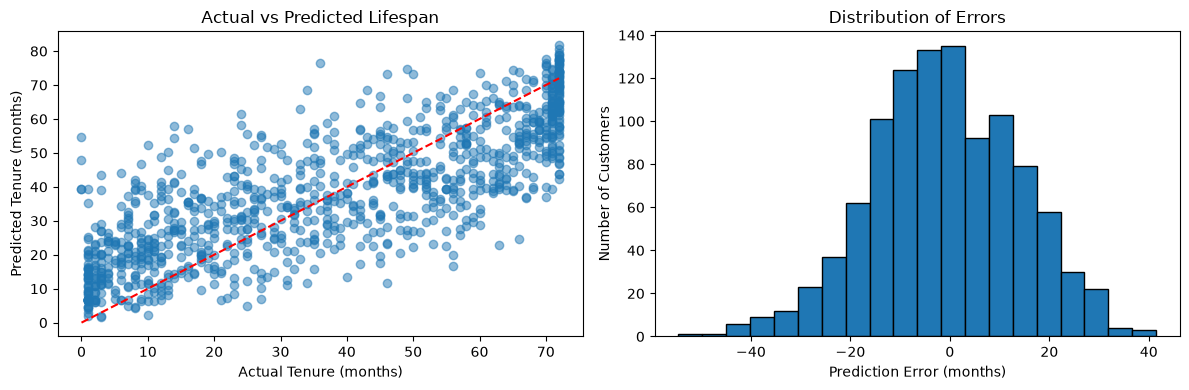

In [42]:
best_reg_name = reg_df.loc[reg_df["RMSE"].idxmin(), "Model"]
best_reg = reg_models[best_reg_name]
print("Best regression model:", best_reg_name)

y_reg_pred = best_reg.predict(X_reg_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_reg_test, y_reg_pred, alpha=0.5)
axes[0].plot([0, 72], [0, 72], linestyle="--", color="red")
axes[0].set_xlabel("Actual Tenure (months)")
axes[0].set_ylabel("Predicted Tenure (months)")
axes[0].set_title("Actual vs Predicted Lifespan")

errors = y_reg_test - y_reg_pred
axes[1].hist(errors, bins=20, edgecolor="black")
axes[1].set_xlabel("Prediction Error (months)")
axes[1].set_ylabel("Number of Customers")
axes[1].set_title("Distribution of Errors")

plt.tight_layout()
plt.show()

The R2 of about 0.62 means the model explains a bit under two thirds of the variation in how long a customer stays, with an average error of roughly 12 months. That is far from precise, but predicting the exact month somebody leaves is genuinely hard and the dataset has nothing about competitor offers or service quality. We only use this number to get a rough size for how much money is at stake, never as a decision on its own.

## Part 17 - Revenue at Risk

Now we combine the two models. The classifier gives the probability that a customer leaves, and
the regression estimates how long they would stay if we kept them. Multiplying those by the
monthly bill gives a rough figure for the money the company loses if that customer walks away:

    Revenue at Risk = churn probability x monthly charges x expected months remaining

This turns the model output into something the company can act on, because it can sort the
customers and call the expensive ones first instead of treating every at-risk customer the same.

In [43]:
# Score the test set customers, these were never used for training or model selection
risk_df = X_test.copy()

risk_df["ChurnProbability"] = best_model.predict_proba(X_test)[:, 1]

# The regression needs the same columns it was trained on
predicted_lifespan = best_reg.predict(X_test[X_reg.columns])

# Linear Regression has no idea that a lifespan cannot be negative or longer than the
# 72 months in the dataset, so it sometimes predicts impossible values. About 2% of
# predictions fall outside that range, so we clip them back to something sensible.
print("Before clipping: min %.1f, max %.1f months" % (predicted_lifespan.min(), predicted_lifespan.max()))
predicted_lifespan = np.clip(predicted_lifespan, 1, 72)
print("After clipping:  min %.1f, max %.1f months" % (predicted_lifespan.min(), predicted_lifespan.max()))

# If the customer has already lasted longer than predicted, treat the remaining time as 0
# rather than letting it go negative.
risk_df["ExpectedMonthsLeft"] = np.maximum(predicted_lifespan - risk_df["tenure"], 0)

risk_df["RevenueAtRisk"] = (
    risk_df["ChurnProbability"] * risk_df["MonthlyCharges"] * risk_df["ExpectedMonthsLeft"]
)

print("Total revenue at risk across the test customers: $" + str(round(risk_df["RevenueAtRisk"].sum(), 2)))
print("Average per customer: $" + str(round(risk_df["RevenueAtRisk"].mean(), 2)))

Before clipping: min -0.4, max 81.8 months
After clipping:  min 1.0, max 72.0 months
Total revenue at risk across the test customers: $390365.91
Average per customer: $277.05


In [44]:
priority_list = risk_df.sort_values("RevenueAtRisk", ascending=False)

top20 = priority_list[["tenure", "MonthlyCharges", "ChurnProbability", "ExpectedMonthsLeft", "RevenueAtRisk"]].head(20)
print("Top 20 customers to contact first:")
top20.round(2)

Top 20 customers to contact first:


,tenure,MonthlyCharges,ChurnProbability,ExpectedMonthsLeft,RevenueAtRisk
6894,3,105.90,0.94,41.16,4095.09
3085,3,105.35,0.91,36.25,3458.64
6024,3,91.50,0.90,37.11,3049.82
1176,6,109.90,0.82,32.58,2934.80
6365,7,101.95,0.93,31.04,2931.73
3837,4,105.65,0.71,38.74,2919.16
383,1,90.85,0.94,32.19,2745.10
1568,11,111.40,0.87,27.25,2627.93
2493,6,90.75,0.89,30.43,2468.41
4800,1,94.00,0.98,25.96,2382.71


If we call the 100 customers with the highest churn probability:
  revenue covered: $141558.86
If we call the 100 customers with the highest revenue at risk:
  revenue covered: $178793.93


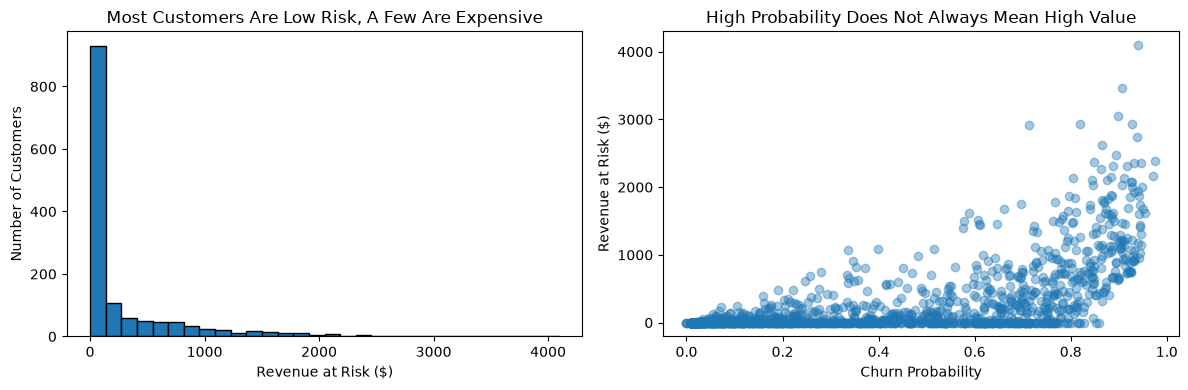

In [45]:
# Compare the two ways of ranking customers
by_probability = risk_df.sort_values("ChurnProbability", ascending=False).head(100)
by_revenue = risk_df.sort_values("RevenueAtRisk", ascending=False).head(100)

print("If we call the 100 customers with the highest churn probability:")
print("  revenue covered: $" + str(round(by_probability["RevenueAtRisk"].sum(), 2)))
print("If we call the 100 customers with the highest revenue at risk:")
print("  revenue covered: $" + str(round(by_revenue["RevenueAtRisk"].sum(), 2)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(risk_df["RevenueAtRisk"], bins=30, edgecolor="black")
axes[0].set_xlabel("Revenue at Risk ($)")
axes[0].set_ylabel("Number of Customers")
axes[0].set_title("Most Customers Are Low Risk, A Few Are Expensive")

axes[1].scatter(risk_df["ChurnProbability"], risk_df["RevenueAtRisk"], alpha=0.4)
axes[1].set_xlabel("Churn Probability")
axes[1].set_ylabel("Revenue at Risk ($)")
axes[1].set_title("High Probability Does Not Always Mean High Value")

plt.tight_layout()
plt.show()

The scatter plot on the right is the point of this section. The customers with the highest churn
probability are not always the ones worth the most money, so ranking by probability alone would
send the retention team after the wrong people.

## Part 18 - What-If Retention Tool

Knowing a customer is at risk still does not tell the company what to *do* about it. This
section takes a customer and tries out the changes the company could realistically offer, then
re-runs the model on each version to see which change lowers their churn risk the most.

Because the data is one-hot encoded, switching a customer to a different contract means setting
all the `Contract_` columns to 0 and then setting the one we want to 1. The columns that were
removed by `drop_first=True` are the reference categories, so setting every dummy in that group
to 0 is how we select them (for example all `PaymentMethod_` columns at 0 means bank transfer).

In [46]:
def set_category(customer_row, prefix, chosen_column=None):
    """Return a copy of the customer with one categorical feature changed."""
    changed = customer_row.copy()

    for col in changed.index:
        if col.startswith(prefix + "_"):
            changed[col] = 0

    if chosen_column is not None:
        changed[chosen_column] = 1

    return changed


def add_service(customer_row, service_column):
    """Turn on an add-on service and update the TotalServices count to match."""
    changed = customer_row.copy()

    if changed[service_column] == 0:
        changed[service_column] = 1
        changed["TotalServices"] = changed["TotalServices"] + 1

    return changed


# The offers the company could actually make
def build_options(customer_row):
    return {
        "Move to a 1 year contract": set_category(customer_row, "Contract", "Contract_One year"),
        "Move to a 2 year contract": set_category(customer_row, "Contract", "Contract_Two year"),
        "Add Tech Support": add_service(customer_row, "TechSupport_Yes"),
        "Add Online Security": add_service(customer_row, "OnlineSecurity_Yes"),
        "Switch to automatic bank payment": set_category(customer_row, "PaymentMethod"),
        "Turn off paperless billing": set_category(customer_row, "PaperlessBilling")
    }


print("Retention options available:", list(build_options(X_test.iloc[0]).keys()))

Retention options available: ['Move to a 1 year contract', 'Move to a 2 year contract', 'Add Tech Support', 'Add Online Security', 'Switch to automatic bank payment', 'Turn off paperless billing']


In [47]:
def recommend_action(customer_row):
    """Try every retention offer and report how much each one lowers the churn risk."""
    original_risk = best_model.predict_proba(customer_row.to_frame().T)[0, 1]

    rows = []
    for action, changed_row in build_options(customer_row).items():
        new_risk = best_model.predict_proba(changed_row.to_frame().T)[0, 1]
        rows.append({
            "Action": action,
            "New Risk": new_risk,
            "Risk Drop": original_risk - new_risk
        })

    result = pd.DataFrame(rows).sort_values("Risk Drop", ascending=False).reset_index(drop=True)
    return original_risk, result


# Try it on the customer with the highest revenue at risk
target_customer = priority_list.iloc[0][X_test.columns]
current_risk, actions = recommend_action(target_customer)

print("Customer currently on:")
print("  tenure:", int(target_customer["tenure"]), "months")
print("  monthly charges: $" + str(round(target_customer["MonthlyCharges"], 2)))
print("  current churn risk:", str(round(current_risk * 100, 1)) + "%")
print()
actions.round(3)

Customer currently on:
  tenure: 3 months
  monthly charges: $105.9
  current churn risk: 94.0%



,Action,New Risk,Risk Drop
0,Move to a 2 year contract,0.762,0.178
1,Move to a 1 year contract,0.879,0.061
2,Switch to automatic bank payment,0.914,0.026
3,Turn off paperless billing,0.916,0.024
4,Add Online Security,0.933,0.006
5,Add Tech Support,0.935,0.005


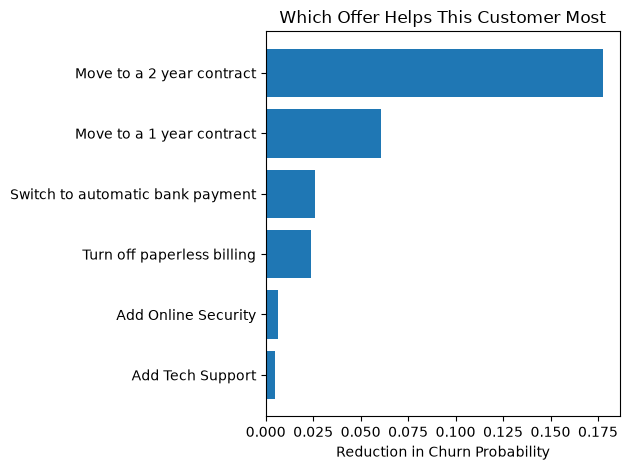

Recommended action: Move to a 2 year contract
Churn risk would go from 94.0% to 76.2%


In [48]:
plt.barh(actions["Action"], actions["Risk Drop"])
plt.xlabel("Reduction in Churn Probability")
plt.title("Which Offer Helps This Customer Most")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

best_action = actions.loc[0, "Action"]
print("Recommended action:", best_action)
print("Churn risk would go from", str(round(current_risk * 100, 1)) + "%",
      "to", str(round(actions.loc[0, "New Risk"] * 100, 1)) + "%")

Best action for each of the top 50 customers:
Move to a 2 year contract    50
Name: count, dtype: int64


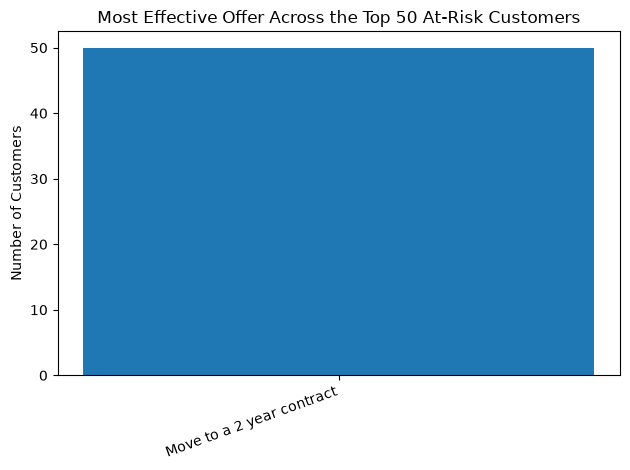

In [49]:
# Run the recommender across the top 50 customers to see which offer comes up most often
recommendations = []

for i in range(50):
    row = priority_list.iloc[i][X_test.columns]
    _, action_table = recommend_action(row)
    recommendations.append(action_table.loc[0, "Action"])

recommendation_counts = pd.Series(recommendations).value_counts()
print("Best action for each of the top 50 customers:")
print(recommendation_counts)

plt.bar(recommendation_counts.index, recommendation_counts.values)
plt.ylabel("Number of Customers")
plt.title("Most Effective Offer Across the Top 50 At-Risk Customers")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

The same offer comes out on top for all 50 customers, which looked like a bug at first. It is
not. Going back to the coefficients in Part 15, `Contract_Two year` is -0.68 while
`TechSupport_Yes` is only -0.08, so a two year contract is roughly eight times stronger than any
other offer we can make. Every one of these top 50 customers is on a month-to-month plan, so the
contract switch always wins.

What does change between customers is *how much* it helps. For the customer above the risk only
drops from 94% to 76%, because their other risk factors (very short tenure, fiber optic, high
bill) do not go away. So the tool is still useful for setting expectations: it shows that for
some customers even the best available offer will probably not be enough to keep them, and the
company may be better off spending that effort elsewhere.

## Part 19 - Does the Threshold Actually Make Money?

In Part 12 we picked the threshold by maximising the F2-score, on the argument that missing a
churner is worse than a false alarm. That is a reasonable argument but it is still just an
argument. F2 assumes a missed churner is exactly twice as bad as a false alarm, and nobody
checked whether that is true.

Now that Part 17 gives us a dollar value for each customer we can test it properly. For a
retention campaign the company gains money when it contacts a real churner and keeps them, and
loses money on every offer sent to somebody who was never going to leave:

    profit = (churners we contact and keep) x (their remaining revenue) - (everyone contacted) x (cost per offer)

There is one number we cannot get from the data: the **save rate**, meaning how many of the
customers we contact actually change their mind and stay. That depends on how good the offer is,
so instead of guessing one value we try a range and see whether the answer changes.

In [50]:
# What a saved customer is actually worth: the revenue they would still have paid us
customer_value = risk_df["MonthlyCharges"] * risk_df["ExpectedMonthsLeft"]

print("Value of keeping one churner:")
print("  mean:   $", round(customer_value[y_test == 1].mean(), 2))
print("  median: $", round(customer_value[y_test == 1].median(), 2))


def campaign_profit(threshold, offer_cost, save_rate):
    """Profit from running a retention campaign at this threshold."""
    contacted = risk_df["ChurnProbability"] >= threshold

    # We only earn money on the people who were really going to leave AND who the offer works on
    real_churners_contacted = contacted & (y_test == 1)
    money_saved = customer_value[real_churners_contacted].sum() * save_rate

    # But we pay for every single offer, including the wasted ones
    money_spent = contacted.sum() * offer_cost

    return money_saved - money_spent


print("\nExample: threshold 0.3, $50 offer, 30% of contacted churners stay")
print("Profit: $", round(campaign_profit(0.3, 50, 0.30), 2))

Value of keeping one churner:
  mean:   $ 811.76
  median: $ 576.5

Example: threshold 0.3, $50 offer, 30% of contacted churners stay
Profit: $ 47985.16


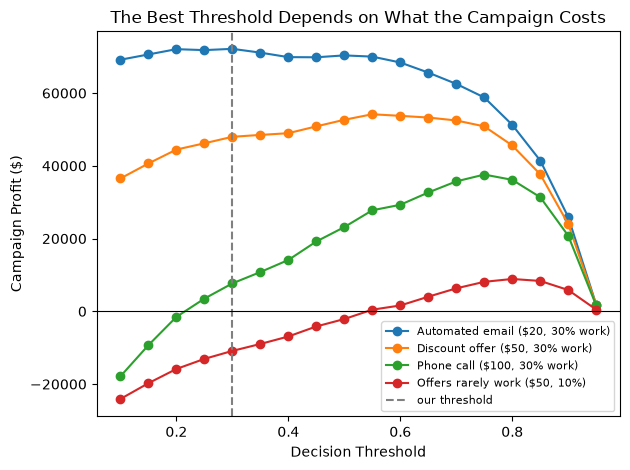

,Campaign,Best threshold,Profit at best,Profit at our 0.3
0,"Automated email ($20, 30% work)",0.30,72165.16,72165.16
1,"Discount offer ($50, 30% work)",0.55,54184.29,47985.16
2,"Phone call ($100, 30% work)",0.75,37603.06,7685.16
3,"Offers rarely work ($50, 10%)",0.80,8902.04,-10871.61


In [51]:
# Four campaigns the company might realistically run
scenarios = {
    "Automated email ($20, 30% work)": (20, 0.30),
    "Discount offer ($50, 30% work)": (50, 0.30),
    "Phone call ($100, 30% work)": (100, 0.30),
    "Offers rarely work ($50, 10%)": (50, 0.10)
}

profit_results = []

for name, (offer_cost, save_rate) in scenarios.items():
    profits = [campaign_profit(t, offer_cost, save_rate) for t in thresholds]
    best_index = int(np.argmax(profits))

    profit_results.append({
        "Campaign": name,
        "Best threshold": thresholds[best_index],
        "Profit at best": profits[best_index],
        "Profit at our 0.3": campaign_profit(0.3, offer_cost, save_rate)
    })

    plt.plot(thresholds, profits, marker="o", label=name)

plt.axvline(best_threshold, color="grey", linestyle="--", label="our threshold")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Decision Threshold")
plt.ylabel("Campaign Profit ($)")
plt.title("The Best Threshold Depends on What the Campaign Costs")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(profit_results).round(2)

This is the part worth paying attention to. There is **no single correct threshold**.

If the offer is cheap, contacting almost everybody is worth it and a low threshold like ours
wins. As the offer gets more expensive, or as fewer customers respond to it, the wasted offers
start costing more than the saved customers are worth, and the best threshold moves up. In the
worst case shown here a low threshold actually loses the company money.

So our choice of 0.3 is not correct in general, it is correct **for a cheap automated campaign**.
That is a fair assumption for something like an email, and it is the assumption we are making,
but it needs to be stated rather than hidden. It is also the reason the Streamlit app exposes the
threshold as a slider instead of fixing it in the code: the right value is a business decision
about budget, not something the model can work out on its own.

In [52]:
# How much does getting the threshold wrong actually cost?
comparison = []

for name, (offer_cost, save_rate) in scenarios.items():
    profits = np.array([campaign_profit(t, offer_cost, save_rate) for t in thresholds])
    best_profit = profits.max()
    our_profit = campaign_profit(best_threshold, offer_cost, save_rate)

    comparison.append({
        "Campaign": name,
        "Best possible": best_profit,
        "Ours (0.3)": our_profit,
        "Money lost": best_profit - our_profit,
        "% of best": 100 * our_profit / best_profit if best_profit > 0 else np.nan
    })

comparison_profit_df = pd.DataFrame(comparison)
print("How well does our single threshold hold up across the four campaigns?")
comparison_profit_df.round(2)

How well does our single threshold hold up across the four campaigns?


,Campaign,Best possible,Ours (0.3),Money lost,% of best
0,"Automated email ($20, 30% work)",72165.16,72165.16,0.00,100.00
1,"Discount offer ($50, 30% work)",54184.29,47985.16,6199.13,88.56
2,"Phone call ($100, 30% work)",37603.06,7685.16,29917.89,20.44
3,"Offers rarely work ($50, 10%)",8902.04,-10871.61,19773.65,-122.12


Our threshold is close to optimal for the two cheap campaigns, but it gives up a lot of money
on the expensive ones. If the company only ever runs one kind of campaign it should pick the
threshold to match that campaign, and if it runs several it needs a different threshold for each,
which is exactly what the slider in the app is for.

## Part 20 - Who Should We Actually Contact?

Part 19 showed that no single threshold works for every campaign. But there is a bigger problem
with using a threshold at all, and it only became obvious once we looked at the false alarm count.

At our threshold of 0.30 the model contacts **806 of the 1,409 test customers**. Of those, 459 were
never going to leave, which means we hand a retention offer to 44% of our loyal customers. If the
offer is a real discount rather than an email that is very expensive, because we are giving money
away to people who were happily paying full price.

The reason is that a threshold only looks at the **probability** and ignores the **value**. It
treats a customer paying $20 a month exactly the same as one paying $110 a month. But those two
customers are not worth the same effort, and Part 17 already worked out what each one is worth.

So instead of one threshold for everybody, we decide customer by customer. Contact somebody only
if what we expect to gain from them is bigger than what it costs to make them the offer:

    contact if (churn probability x their value x save rate) > cost of the offer for them

This is really just the same idea as Part 12 but applied per person instead of once globally.

In [53]:
# What each customer is worth if we keep them, from Part 17
customer_value = risk_df["MonthlyCharges"] * risk_df["ExpectedMonthsLeft"]

# Expected gain from contacting each customer
save_rate = 0.30
expected_gain = risk_df["ChurnProbability"] * customer_value * save_rate

# Two ways the company might make an offer
flat_offer_cost = 50.0
discount_cost = risk_df["MonthlyCharges"] * 0.20 * 12   # 20% off for a year

print("Cost of a 20% discount, per customer:")
print("  cheapest: $", round(discount_cost.min(), 2))
print("  average:  $", round(discount_cost.mean(), 2))
print("  dearest:  $", round(discount_cost.max(), 2))

print("\nExpected gain from contacting a customer:")
print("  average:  $", round(expected_gain.mean(), 2))
print("  highest:  $", round(expected_gain.max(), 2))

Cost of a 20% discount, per customer:
  cheapest: $ 43.8
  average:  $ 154.93
  dearest:  $ 279.0

Expected gain from contacting a customer:
  average:  $ 83.12
  highest:  $ 1228.53


In [54]:
def campaign_summary(contact_mask, cost_per_customer, label):
    """Work out how a contact strategy performs."""
    real_churners = contact_mask & (y_test == 1)
    false_alarms = contact_mask & (y_test == 0)

    money_saved = (customer_value[real_churners] * save_rate).sum()

    if np.isscalar(cost_per_customer):
        money_spent = contact_mask.sum() * cost_per_customer
    else:
        money_spent = cost_per_customer[contact_mask].sum()

    return {
        "Strategy": label,
        "Contacted": int(contact_mask.sum()),
        "Churners caught": int(real_churners.sum()),
        "False alarms": int(false_alarms.sum()),
        "Profit": money_saved - money_spent
    }


# Compare our threshold against picking customer by customer
results_flat = [
    campaign_summary(risk_df["ChurnProbability"] >= best_threshold, flat_offer_cost,
                     f"Threshold {best_threshold:.2f} (what we use now)"),
    campaign_summary(risk_df["ChurnProbability"] >= 0.50, flat_offer_cost,
                     "Threshold 0.50"),
    campaign_summary(expected_gain > flat_offer_cost, flat_offer_cost,
                     "Contact only if it pays off")
]

print("Using a flat $50 offer:")
pd.DataFrame(results_flat).round(2)

Using a flat $50 offer:


,Strategy,Contacted,Churners caught,False alarms,Profit
0,Threshold 0.30 (what we use now),806,347,459,47985.16
1,Threshold 0.50,590,301,289,52662.96
2,Contact only if it pays off,450,231,219,65775.22


In [55]:
results_discount = [
    campaign_summary(risk_df["ChurnProbability"] >= best_threshold, discount_cost,
                     f"Threshold {best_threshold:.2f} (what we use now)"),
    campaign_summary(risk_df["ChurnProbability"] >= 0.50, discount_cost,
                     "Threshold 0.50"),
    campaign_summary(expected_gain > discount_cost, discount_cost,
                     "Contact only if it pays off")
]

print("Using a 20% discount for a year (much more expensive per customer):")
pd.DataFrame(results_discount).round(2)

Using a 20% discount for a year (much more expensive per customer):


,Strategy,Contacted,Churners caught,False alarms,Profit
0,Threshold 0.30 (what we use now),806,347,459,-50875.72
1,Threshold 0.50,590,301,289,-26140.64
2,Contact only if it pays off,265,167,98,26774.94


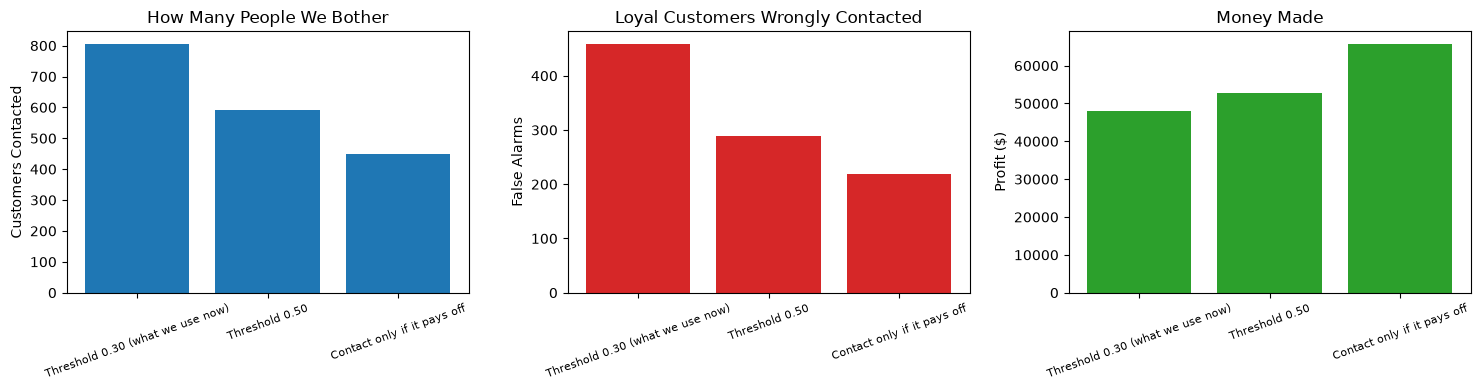

In [56]:
# Show the difference visually, using the flat offer case
summary_df = pd.DataFrame(results_flat)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(summary_df["Strategy"], summary_df["Contacted"])
axes[0].set_ylabel("Customers Contacted")
axes[0].set_title("How Many People We Bother")

axes[1].bar(summary_df["Strategy"], summary_df["False alarms"], color="tab:red")
axes[1].set_ylabel("False Alarms")
axes[1].set_title("Loyal Customers Wrongly Contacted")

axes[2].bar(summary_df["Strategy"], summary_df["Profit"], color="tab:green")
axes[2].set_ylabel("Profit ($)")
axes[2].set_title("Money Made")

for ax in axes:
    ax.tick_params(axis="x", rotation=20, labelsize=8)

plt.tight_layout()
plt.show()

Customers the threshold would contact but targeting skips: 390
  their average monthly bill: $ 67.84
  their average churn risk:   0.537

Customers targeting keeps: 450
  their average monthly bill: $ 75.88
  their average churn risk:   0.697


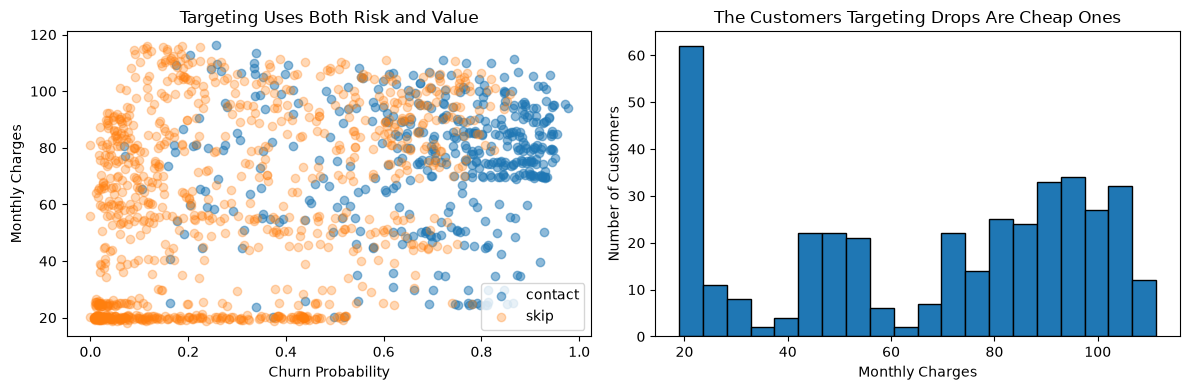

In [57]:
# Why does it work? Look at who gets dropped.
targeted = expected_gain > flat_offer_cost
threshold_only = risk_df["ChurnProbability"] >= best_threshold

dropped = threshold_only & (~targeted)
print("Customers the threshold would contact but targeting skips:", dropped.sum())
print("  their average monthly bill: $", round(risk_df.loc[dropped, "MonthlyCharges"].mean(), 2))
print("  their average churn risk:  ", round(risk_df.loc[dropped, "ChurnProbability"].mean(), 3))
print()
print("Customers targeting keeps:", targeted.sum())
print("  their average monthly bill: $", round(risk_df.loc[targeted, "MonthlyCharges"].mean(), 2))
print("  their average churn risk:  ", round(risk_df.loc[targeted, "ChurnProbability"].mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(risk_df.loc[targeted, "ChurnProbability"], risk_df.loc[targeted, "MonthlyCharges"],
                alpha=0.5, label="contact")
axes[0].scatter(risk_df.loc[~targeted, "ChurnProbability"], risk_df.loc[~targeted, "MonthlyCharges"],
                alpha=0.3, label="skip")
axes[0].set_xlabel("Churn Probability")
axes[0].set_ylabel("Monthly Charges")
axes[0].set_title("Targeting Uses Both Risk and Value")
axes[0].legend()

axes[1].hist(risk_df.loc[dropped, "MonthlyCharges"], bins=20, edgecolor="black")
axes[1].set_xlabel("Monthly Charges")
axes[1].set_ylabel("Number of Customers")
axes[1].set_title("The Customers Targeting Drops Are Cheap Ones")

plt.tight_layout()
plt.show()

This is the most useful thing we found in the whole project, and we only found it because the
false alarm count looked too high.

Targeting contacts far fewer people, raises fewer false alarms, and still makes more money than any
single threshold. It catches fewer churners in total, which looks worse if you only read the recall
number, but the ones it gives up on are the cheap customers where a $50 offer costs more than the
revenue we would save. Spending $50 to keep a customer worth $30 is a bad trade no matter how
likely they are to leave.

The gap gets much bigger when the offer is expensive. With a real discount, our threshold of 0.30
actually loses money, while targeting still makes a profit, because targeting automatically refuses
to give a large discount to a customer whose bill is too small to justify it.

So the honest conclusion is that the threshold answers the question "is this customer likely to
leave", which is a **modelling** question, but it does not answer "should we spend money on this
customer", which is a **business** question. We need both, and we were previously only doing the
first one.

## Part 21 - Save the Models

In [58]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/churn_pipeline.joblib")
joblib.dump(best_reg, "../models/lifespan_model.joblib")

# The app needs the column order and the options for each input field, otherwise it cannot
# rebuild the same one-hot columns for a new customer.
model_info = {
    "best_model_name": best_model_name,
    "best_reg_name": best_reg_name,
    "threshold": float(best_threshold),
    # assumptions behind the targeting rule in Part 20, so the app can use the same numbers
    "save_rate": save_rate,
    "flat_offer_cost": flat_offer_cost,
    "test_metrics": test_metrics,
    "regression_metrics": reg_df.set_index("Model").loc[best_reg_name].to_dict(),
    "feature_columns": X_train.columns.tolist(),
    "regression_columns": X_reg.columns.tolist(),
    "service_cols": service_cols,
    "category_options": {
        col: sorted(clean_df[col].unique().tolist())
        for col in categorical_cols if col != "TenureGroup"
    },
    "numeric_ranges": {
        col: {
            "min": float(clean_df[col].min()),
            "max": float(clean_df[col].max()),
            "median": float(clean_df[col].median())
        }
        for col in ["tenure", "MonthlyCharges", "TotalCharges"]
    }
}

joblib.dump(model_info, "../models/churn_metadata.joblib")

loaded_model = joblib.load("../models/churn_pipeline.joblib")
print("Models saved and loaded successfully.")

Models saved and loaded successfully.


## Conclusion and Business Insights

**Model chosen:** Logistic Regression, tuned with GridSearchCV (`C=10`,
`class_weight="balanced"`), with the decision threshold set to 0.30 from the threshold
experiment in Part 12 instead of the default 0.5.

**Final test results:** Accuracy 0.655, Precision 0.431, Recall 0.928, F1-score 0.588,
F2-score 0.754.

Out of the 374 real churners in the test set the model catches 347 and misses only 27. It
raises 459 false alarms to do that.

That trade is deliberate. We chose the threshold by maximising **F2** rather than F1, because F2
weights recall twice as heavily as precision, and for this business the two mistakes are not
equally costly. Part 17 estimates an at-risk customer is worth about $277 on average and over
$1,500 at the top end, while a retention discount costs the company maybe $20 to $50. Sending an
unnecessary discount is cheap; losing a customer is not.

If we had optimised F1 instead, the threshold would have been 0.60, which looks better on paper
(accuracy 0.767, precision 0.546) but only catches 267 churners instead of 347. It would let 80
more customers walk out of the door in exchange for saving 237 discount offers, which is the
wrong way round given the numbers above.

Logistic Regression beat Random Forest, SVM and the Neural Network even though it is the
simplest of the five. Once the data is scaled and encoded the churn boundary is close to a
straight line, so the more flexible models mostly just overfitted (the MLP had a train/validation
gap of 0.268 in Part 10) instead of generalising better. The cross-validation in Part 14
confirms this is not luck from one split: Logistic Regression came first in all 5 folds and had
the smallest standard deviation (0.004).

**What the coefficients tell us**

Pushes a customer towards churning:
- Fiber optic internet (+1.02), by far the strongest service-related factor
- Streaming Movies (+0.36) and Streaming TV (+0.30)
- Paying by electronic check (+0.18) and paperless billing (+0.18)

Keeps a customer:
- Longer tenure (-1.14)
- Two year contract (-0.68) and one year contract (-0.31)

**Recommendations for the company:**
1. Move month-to-month customers onto 1 or 2 year contracts, for example with a discount for
   committing. Contract length is the clearest lever in the model and it is something the
   company directly controls.
2. Investigate the fiber optic customers, since they have the strongest positive coefficient.
   It is most likely a price or reliability complaint rather than the technology itself, so a
   customer survey would be the sensible next step.
3. Focus retention effort on new customers. Tenure has a large negative coefficient, meaning
   the risk is highest in the first months, so an onboarding follow-up in the first year would
   target the right people.
4. Encourage electronic check users to move to automatic payment. The effect is smaller than
   contract length, but switching payment method is cheap to do.

**Limitations:**
- Precision is only 0.431, so well over half of the customers we flag would not actually have
  left. We are deliberately accepting that in exchange for the high recall, but it does mean the
  retention team would be contacting 806 of the 1,409 test customers, which is a large share of
  the customer base. If the intervention were expensive (a personal phone call rather than an
  automated email) this threshold would be too aggressive and should be raised.
- F2 encodes an assumption that a missed churner is exactly twice as bad as a false alarm, which
  is a guess rather than a measured fact. Part 19 tests that guess against actual money and finds
  it only holds for a cheap campaign. Our threshold of 0.3 is exactly optimal for a $20 automated
  email, keeps 89% of the available profit on a $50 discount, but collects only 20% of it on a
  $100 phone call, and actually **loses** about $10,900 if retention offers only work on 10% of
  the people contacted. So the threshold is right for the campaign we assumed, not right in
  general, and the company would need to re-pick it for each campaign it runs.
- Several features overlap (see the note in Part 15), so the individual coefficients for the
  charge columns cannot be trusted on their own.
- The coefficients show correlation, not cause. Fiber optic customers churning more does not
  prove fiber optic causes churn, so recommendation 2 needs to be checked with a survey before
  acting on it.

---

## Extension: Turning the Prediction into a Decision

The classification model on its own only answers "will this customer leave". Parts 16 to 18 turn
that into something the company can act on.

**Predicting customer lifespan (Part 16).** A Linear Regression trained on the customers who have
*not* churned predicts how long a retained customer stays, with an MAE of 12.0 months and an R2
of 0.622. That is much weaker than the classification result, and we only use it to get a rough
size for the money at stake rather than as a decision on its own.

Our first attempt trained this model on the customers who had already left, which seemed like the
obvious choice because their lifespan is known. It was wrong. That model learned how quickly
people leave, so for the highest risk customers it predicted a lifespan shorter than the time they
had already been with the company, and their revenue at risk came out as exactly $0. The
customers we care about most were being reported as worth nothing. Training on the retained
customers instead fixed that and also gave a better R2 (0.622 against 0.584).

**Revenue at risk (Part 17).** Combining the two models gives
`churn probability x monthly charges x expected months remaining`. Across the test customers that
comes to about $390,000 at risk in total, or an average of $277 per customer.

The useful part is what it does to prioritisation. If the retention team can only call 100
customers:
- calling the 100 with the highest churn *probability* covers about $141,600 of revenue
- calling the 100 with the highest revenue *at risk* covers about $178,800

That is roughly 26% more money protected for exactly the same number of phone calls, purely from
ranking the same customers differently. This is the argument for adding the regression model
rather than stopping at classification.

**What-if retention tool (Part 18).** For any customer the tool re-runs the model with each
retention offer applied and reports which one lowers their risk the most. For the highest value
at-risk customer, moving them to a two year contract drops their churn probability from 94% to
76%.

Across the top 50 customers the two year contract was the best offer every time, which matches
the coefficient analysis in Part 15. The value is in the size of the drop rather than the choice
of offer: it shows which customers can realistically be saved and which are likely to leave
regardless, so the company does not waste discounts on people who are going anyway.

**Does the threshold actually make money (Part 19).** Because Part 17 gives a dollar value per
customer, we could finally check the assumption behind our threshold instead of just arguing for
it. Modelling a retention campaign as
`(churners kept x their remaining revenue) - (everyone contacted x cost per offer)` shows that the
best threshold moves with the cost of the campaign: 0.30 for a $20 automated email, 0.55 for a $50
discount, 0.75 for a $100 phone call, and 0.80 if offers only work on one customer in ten.

The honest conclusion is that there is no single correct threshold. Ours is optimal for a cheap
automated campaign and clearly wrong for an expensive one, which is why the app exposes it as a
slider rather than hard-coding it.

**Who should we actually contact (Part 20).** Part 19 left one problem unsolved. At our threshold
of 0.30 the model contacts 806 of the 1,409 test customers, and 459 of those were never going to
leave, so 44% of our loyal customers receive a retention offer. That is a lot of money given away
to people who were happily paying full price.

The cause is that a threshold only looks at the probability and ignores the value. It treats a
customer paying $20 a month exactly like one paying $110 a month, even though Part 17 already
told us what each one is worth. So instead of one cut-off for everybody we decide per customer,
and contact somebody only when `churn probability x their value x save rate` is bigger than what
the offer costs for them.

With a flat $50 offer:

| Strategy | Contacted | Churners caught | False alarms | Profit |
|---|---|---|---|---|
| Threshold 0.30 | 806 | 347 | 459 | $47,985 |
| Threshold 0.50 | 590 | 301 | 289 | $52,663 |
| **Contact only if it pays off** | **450** | 231 | **219** | **$65,775** |

Targeting contacts 356 fewer people, halves the false alarms, and still makes 37% more money than
our threshold. It catches fewer churners, which looks worse on recall alone, but the ones it drops
are cheap customers where a $50 offer costs more than the revenue it would save.

The gap becomes decisive when the offer is expensive. With a 20% discount for a year (about $155
per customer on average) the threshold strategies **lose** money, $50,876 at 0.30 and $26,141 at
0.50, while targeting still returns a $26,775 profit because it automatically refuses to hand a
large discount to a customer whose bill is too small to justify it.

The lesson is that the threshold answers "is this customer likely to leave", which is a modelling
question, while "should we spend money on this customer" is a business question that needs the
value as well. We were previously only answering the first one and assuming it covered both.

**Limitations of the extension:**
- The lifespan model is trained on customers who are still with the company, so their tenure is
  how long they have stayed *so far*, not their final lifespan. That means the model
  systematically under-estimates how long a loyal customer would stay, and the real revenue at
  risk is probably higher than the figures above.
- Linear Regression is a straight line and has no concept of a valid range, so it predicted
  lifespans between -0.4 and 81.8 months when the data only goes from 0 to 72. We clip those back
  into range, but that is a patch rather than a fix, and it gets worse for unusual customer
  combinations that do not appear in the training data.
- The targeting rule depends on a save rate (how many contacted churners actually stay) that the
  dataset cannot tell us. We used 30% throughout. If the true figure were much lower the whole
  campaign stops being worthwhile at any threshold, so this number would need to be measured from
  a real trial before trusting the profit figures.
- The what-if tool assumes that changing a feature *causes* the risk to change. In reality the
  model only learned a correlation. Customers on two year contracts may simply be the type of
  person who was never going to leave anyway, so actually moving somebody onto that contract may
  not produce the full drop the model predicts. Confirming this properly would need an experiment
  where a random group is offered the contract and compared against a control group.

## Reflection Questions
1. Why is accuracy a poor metric for this dataset?
2. Why did we split the data into three sets instead of two?
3. Why must the StandardScaler be fitted inside the Pipeline instead of on the whole dataset?
4. Why did the simplest model beat the more complex ones?
5. Why did we move the decision threshold away from 0.5?
6. Why is revenue at risk a better way to rank customers than churn probability?
7. Why can we not simply trust the what-if tool and assume the offer will work?
8. Why is there no single correct decision threshold?
9. Why does contacting fewer customers make more money than contacting more of them?